# 10 — Evaluación exploratoria de reconocimiento de entidades (NER)

**Objetivo:** evaluar `urchade/gliner_multi-v2.1` sobre 20 noticias muestreadas del corpus de 186, usando las anotaciones manuales confirmadas de los dos lotes. Se aplica coincidencia estricta de `(rss_news_id, start_char, end_char, entity_type)`, que compara cada mención.

**Reproducibilidad y alcance:** muestra aleatoria reproducible (`random_state=20261125`), 20 noticias; clases `person`, `organization`, `location`, `product`; umbral `0.5`. Este es un estudio exploratorio, sin estimación de generalización. La referencia incluye menciones repetidas y menciones de atribución editorial presentes en los textos de entrada. Las noticias sin entidades también se evalúan.

**Fuentes:** `rss_news` (solo lectura), `ner_referencia_20_especificacion.csv` (anotaciones aprobadas). Se realiza una nueva inferencia con idéntica configuración al notebook 06, **sin escribir en PostgreSQL**. Las diferencias entre ejecuciones/modelos/versiones deben documentarse.

## 1. Configuración y recuperación de muestra

Ejecutar desde la raíz del proyecto o desde `notebooks/`. Conservar sin editar las especificaciones manuales. La muestra se reconstruye exactamente mediante su semilla y se comprueban los 20 IDs.

In [1]:
from pathlib import Path
import sys
import re
import pandas as pd
import numpy as np
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.connection import get_connection

CONFIG = {
    "model_name": "urchade/gliner_multi-v2.1",
    "entity_labels": ["person", "organization", "location", "product"],
    "threshold": 0.5,
    "random_state": 20261125,
}
SAMPLE_IDS = [1, 24, 34, 37, 41, 59, 79, 89, 103, 114, 115, 118, 125, 126, 129, 134, 159, 168, 179, 183]

with get_connection() as connection:
    with connection.cursor() as cursor:
        cursor.execute("SELECT rss_news_id, title, description FROM rss_news ORDER BY rss_news_id;")
        columns = [column.name for column in cursor.description]
        all_news = pd.DataFrame(cursor.fetchall(), columns=columns)
assert len(all_news) == 186 and all_news.rss_news_id.is_unique

ner_sample = (
    all_news.sample(n=20, random_state=CONFIG["random_state"])
    .sort_values("rss_news_id")
    .reset_index(drop=True)
)
assert ner_sample.rss_news_id.tolist() == SAMPLE_IDS, "La muestra ya no coincide con la aprobada."

def build_ner_text(row):
    """Reproduce exactamente la preparación de entrada del notebook 06."""
    title = str(row["title"]).strip() if pd.notna(row["title"]) else ""
    description = str(row["description"]).strip() if pd.notna(row["description"]) else ""
    return ". ".join(part for part in [title, description] if part)

ner_sample["ner_text"] = ner_sample.apply(build_ner_text, axis=1)
assert ner_sample.ner_text.str.strip().ne("").all()
print(f"Muestra confirmada: {len(ner_sample)} noticias")


Muestra confirmada: 20 noticias


## 2. Consolidación de anotaciones humanas y cálculo de offsets

El CSV contiene texto, categoría y cantidad de apariciones confirmadas por noticia. Cada aparición se busca en **el texto exacto recuperado de la base** y se registra por separado. `start_char` es inclusivo y `end_char` exclusivo. Una aserción detiene la evaluación si un texto o número de menciones no coincide. Se excluyen coincidencias anidadas de un término dentro de un nombre más largo, p. ej. `Google` dentro de `Google Earth`; `Google` se registra solo donde aparezca independiente.



In [3]:
SPEC_PATH = PROJECT_ROOT / "ner_referencia_20_especificacion.csv"
if not SPEC_PATH.exists():
    SPEC_PATH = Path.cwd() / "ner_referencia_20_especificacion.csv"
assert SPEC_PATH.exists(), f"No encuentro {SPEC_PATH.name}; colocarlo en la raíz del proyecto o junto al notebook."
spec = pd.read_csv(SPEC_PATH, encoding="utf-8-sig")
assert set(spec.columns) == {"rss_news_id", "entity_text", "entity_type", "expected_occurrences"}
assert spec["entity_type"].isin(CONFIG["entity_labels"]).all()
assert set(spec.rss_news_id).issubset(set(SAMPLE_IDS))
assert int(spec.expected_occurrences.sum()) == 38

text_by_id = ner_sample.set_index("rss_news_id")["ner_text"].to_dict()
reference_rows = []
# Procesar menciones largas primero para evitar entidades anidadas.
# Ejemplo: "Google" NO debe contarse dentro de "Google Earth".
for news_id, news_spec in spec.groupby("rss_news_id", sort=True):
    text = text_by_id[int(news_id)]
    occupied = []
    for row in news_spec.sort_values("entity_text", key=lambda s: s.str.len(), ascending=False).itertuples(index=False):
        pattern = rf"(?<!\w){re.escape(row.entity_text)}(?!\w)"
        candidates = list(re.finditer(pattern, text))
        matches = [m for m in candidates if not any(m.start() < end and m.end() > start for start, end in occupied)]
        assert len(matches) == int(row.expected_occurrences), (
            f"ID {news_id} | {row.entity_text!r}: "
            f"esperadas {row.expected_occurrences}, encontradas {len(matches)}. "
            "Revisar el texto original antes de continuar."
        )
        for match in matches:
            occupied.append((match.start(), match.end()))
            reference_rows.append({
                "rss_news_id": int(news_id),
                "entity_text": match.group(),
                "entity_type": row.entity_type,
                "start_char": match.start(),
                "end_char": match.end(),
            })
reference = pd.DataFrame(reference_rows).sort_values(
    ["rss_news_id", "start_char", "end_char", "entity_type"]
).reset_index(drop=True)
assert len(reference) == 38
assert not reference.duplicated(["rss_news_id", "start_char", "end_char", "entity_type"]).any()
for row in reference.itertuples(index=False):
    assert text_by_id[row.rss_news_id][row.start_char:row.end_char] == row.entity_text

reference.to_csv("ner_referencia_20_offsets.csv", index=False, encoding="utf-8-sig")
print("Menciones de referencia:", len(reference))
print(reference.entity_type.value_counts().to_string())
display(reference)


Menciones de referencia: 38
entity_type
product         13
location        10
organization    10
person           5


,rss_news_id,entity_text,entity_type,start_char,end_char
0,1,Google Drive,product,45,57
1,1,Gmail,product,59,64
2,1,Google Fotos,product,67,79
3,37,Android,product,44,51
4,41,WhatsApp,product,22,30
5,59,Nokia 1100,product,0,10
6,59,Snake,product,97,102
7,89,Gemini,product,186,192
8,114,Torre Eiffel,location,3,15
9,114,Google Earth,product,28,40


## 3. Nueva inferencia con GLiNER

Se reutilizan los mismos parámetros y `predict_entities` del notebook 06; se conservan los offsets. 

In [4]:
from gliner import GLiNER

model = GLiNER.from_pretrained(CONFIG["model_name"])
model.eval()

prediction_rows = []
for row in ner_sample.itertuples(index=False):
    outputs = model.predict_entities(
        text=row.ner_text,
        labels=CONFIG["entity_labels"],
        threshold=CONFIG["threshold"],
    )
    for entity in outputs:
        start, end = int(entity["start"]), int(entity["end"])
        predicted_text = entity["text"].strip()
        if not predicted_text:
            continue
        assert row.ner_text[start:end].strip() == predicted_text, (
            f"El texto y los offsets devueltos no coinciden en ID {row.rss_news_id}"
        )
        prediction_rows.append({
            "rss_news_id": int(row.rss_news_id),
            "entity_text": predicted_text,
            "entity_type": entity["label"],
            "start_char": start,
            "end_char": end,
            "confidence": float(entity["score"]),
        })

predictions = pd.DataFrame(prediction_rows, columns=[
    "rss_news_id", "entity_text", "entity_type", "start_char", "end_char", "confidence"
])
assert predictions.entity_type.isin(CONFIG["entity_labels"]).all()
assert predictions.confidence.between(0, 1).all()
assert predictions.confidence.ge(CONFIG["threshold"] - 1e-6).all()
assert not predictions.duplicated(["rss_news_id", "start_char", "end_char", "entity_type"]).any()
predictions.to_csv("ner_predicciones_20.csv", index=False, encoding="utf-8-sig")
print("Predicciones generadas:", len(predictions))
display(predictions.head(10))


e:\Trabajo final UGR\communication-intelligence-assistant\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
e:\Trabajo final UGR\communication-intelligence-assistant\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:190: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  warnings.warn(


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Predicciones generadas: 53


,rss_news_id,entity_text,entity_type,start_char,end_char,confidence
0,1,Google Drive,product,45,57,0.873393
1,1,Gmail,product,59,64,0.970584
2,1,Google Fotos,product,67,79,0.918989
3,1,Videos,product,81,87,0.748688
4,1,instaladores,product,110,122,0.567629
5,24,Un robot humanoide,product,0,18,0.624575
6,37,Android,product,44,51,0.575232
7,41,WhatsApp,organization,22,30,0.734688
8,59,Nokia 1100,product,0,10,0.924738
9,59,mundo,location,81,86,0.689747


## 4. Evaluación estricta por mención

TP = coincidencia exacta de noticia, inicio, fin y categoría. FP = mención predicha no anotada; FN = mención anotada no predicha. La evaluación es micro sobre menciones, **sin contar verdaderos negativos**. No se deben eliminar noticias sin entidades de la muestra; contribuyen si contienen FP.

In [5]:
from sklearn.metrics import precision_recall_fscore_support

KEYS = ["rss_news_id", "start_char", "end_char", "entity_type"]
true_set = set(map(tuple, reference[KEYS].itertuples(index=False, name=None)))
pred_set = set(map(tuple, predictions[KEYS].itertuples(index=False, name=None)))

def prf(tp, fp, fn):
    """Precision/Recall/F1 definidos como cero ante denominador nulo."""
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1

rows = []
for label in CONFIG["entity_labels"] + ["micro"]:
    t = {x for x in true_set if label == "micro" or x[3] == label}
    p = {x for x in pred_set if label == "micro" or x[3] == label}
    tp, fp, fn = len(t & p), len(p - t), len(t - p)
    precision, recall, f1 = prf(tp, fp, fn)
    rows.append({"Clase": label, "TP": tp, "FP": fp, "FN": fn, "Soporte": len(t),
                 "Precision": precision, "Recall": recall, "F1": f1})
metrics_df = pd.DataFrame(rows)
assert metrics_df.loc[metrics_df.Clase.eq("micro"), "Soporte"].item() == 38
display(metrics_df.round(4))
metrics_df.to_csv("ner_metricas_20.csv", index=False, encoding="utf-8-sig")


,Clase,TP,FP,FN,Soporte,Precision,Recall,F1
0,person,5,1,0,5,0.8333,1.0000,0.9091
1,organization,10,5,0,10,0.6667,1.0000,0.8000
2,location,8,5,2,10,0.6154,0.8000,0.6957
3,product,7,12,6,13,0.3684,0.5385,0.4375
4,micro,30,23,8,38,0.5660,0.7895,0.6593


## 5. Análisis de errores y exportaciones para el informe

Las tablas permiten inspeccionar menciones omitidas (FN) y detectadas incorrectamente (FP). Los errores de tipo y límites se penalizan como FP + FN. La visualización presenta F1 por categoría y global.

,error,rss_news_id,entity_text,entity_type,start_char,end_char
0,FP,1,Videos,product,81,87
1,FP,1,instaladores,product,110,122
2,FP,24,Un robot humanoide,product,0,18
3,FP,41,WhatsApp,organization,22,30
4,FP,59,mundo,location,81,86
5,FP,79,aura,product,37,41
6,FP,89,Las Guerreras K-pop,organization,15,34
7,FP,89,Gemini,organization,186,192
8,FP,103,celular,product,33,40
9,FP,114,La Torre Eiffel,location,0,15


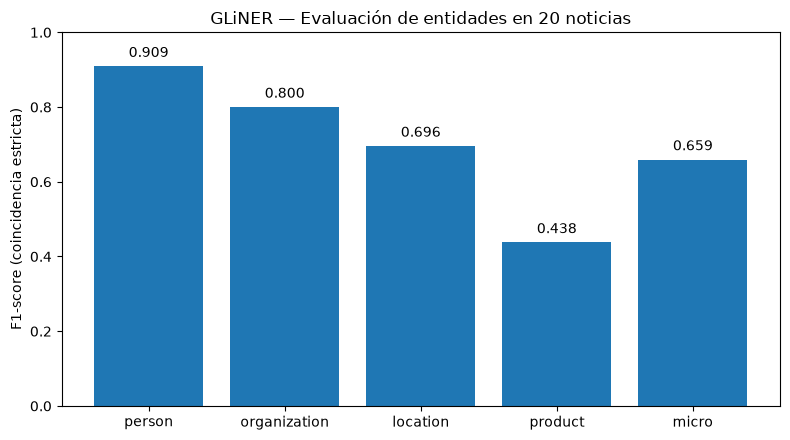

In [6]:
fp_keys, fn_keys = pred_set - true_set, true_set - pred_set
errors = []
for kind, keys in [("FP", fp_keys), ("FN", fn_keys)]:
    for news_id, start, end, label in sorted(keys):
        errors.append({"error": kind, "rss_news_id": news_id, "entity_text": text_by_id[news_id][start:end],
                       "entity_type": label, "start_char": start, "end_char": end})
errors_df = pd.DataFrame(errors, columns=["error", "rss_news_id", "entity_text", "entity_type", "start_char", "end_char"])
display(errors_df)
errors_df.to_csv("ner_errores_20.csv", index=False, encoding="utf-8-sig")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(metrics_df["Clase"], metrics_df["F1"])
ax.set_ylim(0, 1)
ax.set_ylabel("F1-score (coincidencia estricta)")
ax.set_title("GLiNER — Evaluación de entidades en 20 noticias")
for idx, value in enumerate(metrics_df["F1"]):
    ax.text(idx, min(value + 0.025, 0.98), f"{value:.3f}", ha="center")
plt.tight_layout()
fig.savefig("ner_f1_por_clase.png", dpi=300, bbox_inches="tight")
plt.show()


## Conclusiones de la evaluación de NER

La evaluación del modelo `urchade/gliner_multi-v2.1` se realizó sobre una muestra de 20 noticias del corpus original, utilizando 38 menciones de entidades anotadas y confirmadas manualmente.

Se aplicó un criterio de coincidencia estricta, considerando correcta una predicción únicamente cuando coincidían sus posiciones y su categoría con la anotación de referencia.

### Resultados cuantitativos

El modelo alcanzó una **Precision micro de 0,5660, un Recall micro de 0,7895 y un F1-score micro de 0,6593**, identificando correctamente 30 entidades, con 23 falsos positivos y 8 falsos negativos.

El análisis por categoría evidenció diferencias de rendimiento. Las entidades de tipo `person` y `organization` obtuvieron los mejores resultados, con F1-score de 0,9091 y 0,8000, respectivamente. La categoría `location` alcanzó 0,6957, mientras que `product` presentó el menor rendimiento, con 0,4375.

### Análisis de errores

Los principales errores estuvieron asociados con la identificación de términos genéricos como entidades, la confusión entre productos y organizaciones y las diferencias en la delimitación de las menciones.

En particular, se observaron errores al clasificar aplicaciones tecnológicas como organizaciones y al reconocer fragmentos parciales de nombres compuestos.

Estas diferencias resultan relevantes debido al criterio estricto utilizado, que penaliza tanto las categorías incorrectas como las discrepancias en los límites de las entidades.


### Conclusión general

Los resultados muestran que GLiNER permite identificar una proporción considerable de las entidades de referencia, particularmente personas y organizaciones. Sin embargo, presenta limitaciones de precisión, especialmente en la categoría de productos y en la delimitación exacta de determinadas menciones.

En consecuencia, **el componente NER se encuentra funcionalmente implementado y presenta un rendimiento exploratorio moderado**, con oportunidades de mejora en la definición de categorías, el tratamiento de entidades compuestas y la reducción de falsos positivos.
